# M115 Lab 1: Phishing URL Detection — EDA, Parameterized Logistic Regression & SHAP Explainability

---

## ENSIASD Taroudant — Ibn Zohr University
**Master in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027


---

## Lab Overview & Solution Key

This lab focuses on detecting phishing URLs using Machine Learning techniques. It covers Exploratory Data Analysis (EDA), data preprocessing, Logistic Regression, feature selection, and SHAP explainability.

The objective is to develop an interpretable phishing detection model that can support Security Operations Center (SOC) analysts.

---
## 1. Importing Packages & Loading Data

In this section, we import the required Python libraries and configure reproducibility using a fixed random seed.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score
)
import shap

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 4.5)

SEED = 42
np.random.seed(SEED)

In [5]:
import os
import pandas as pd
import numpy as np

file_path = "Dataset/PhiUSIIL_Phishing_URL_Dataset.csv"

print("Dataset exists:", os.path.exists(file_path))

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset exists: True
Dataset Shape: (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


---
## 2 - Part 1: Security-Oriented Exploratory Data Analysis (EDA)

The objective of this part is to explore the dataset, understand its structure, identify data quality issues, and analyze security-related features that can help distinguish phishing URLs from legitimate URLs.

### 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)

First, we inspect the dataset shape, data types, missing values, duplicate rows, and summary statistics across important numerical features.

We also align the target variable with SOC requirements, where 1 represents a phishing URL and 0 represents a legitimate URL.

In [6]:
# EXERCISE 1: Data Quality Inspection

print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nDataset Info:")
df.info()

display(df[['FILENAME', 'URL', 'URLLength', 'LineOfCode',
            'IsHTTPS', 'HasPasswordField', 'NoOfSelfRef', 'label']].head(5))

display(df[['URLLength', 'LineOfCode',
            'CharContinuationRate', 'NoOfSelfRef']].describe().round(2))

Dataset Shape: (235795, 56)
Total Missing Values: 0
Duplicate Rows: 0

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12

,FILENAME,URL,URLLength,LineOfCode,IsHTTPS,HasPasswordField,NoOfSelfRef,label
0,521848.txt,https://www.southbankmosaics.com,31,558,1,0,119,1
1,31372.txt,https://www.uni-mainz.de,23,618,1,0,39,1
2,597387.txt,https://www.voicefmradio.co.uk,29,467,1,0,42,1
3,554095.txt,https://www.sfnmjournal.com,26,6356,1,0,22,1
4,151578.txt,https://www.rewildingargentina.org,33,6089,1,0,72,1


,URLLength,LineOfCode,CharContinuationRate,NoOfSelfRef
count,235795.00,235795.00,235795.00,235795.00
mean,34.57,1141.90,0.85,65.07
std,41.31,3419.95,0.22,176.69
min,13.00,2.00,0.00,0.00
25%,23.00,18.00,0.68,0.00
50%,27.00,429.00,1.00,12.00
75%,34.00,1277.00,1.00,88.00
max,6097.00,442666.00,1.00,27397.00


#### **❗Critical Cyber Label Warning:**


In the original PhiUSIIL dataset:
- label = 1 represents Legitimate (Benign).
- label = 0 represents Phishing (Malicious).

For SOC detection, the positive class must represent the attack. Therefore, we create a new target variable called IsPhishing, where 1 represents Phishing and 0 represents Legitimate.

In [7]:
# EXERCISE 1: SOC Target Alignment

df['IsPhishing'] = 1 - df['label']

phishing_ratio = (df['IsPhishing'] == 1).mean()

print(f"Phishing URLs (1): {(df['IsPhishing'] == 1).sum():,}")
print(f"Legitimate URLs (0): {(df['IsPhishing'] == 0).sum():,}")
print(f"Phishing Proportion: {phishing_ratio * 100:.2f}%")

print("\nNormalized Class Proportions:")
print(df['IsPhishing'].value_counts(normalize=True).round(4))

Phishing URLs (1): 100,945
Legitimate URLs (0): 134,850
Phishing Proportion: 42.81%

Normalized Class Proportions:
IsPhishing
0    0.5719
1    0.4281
Name: proportion, dtype: float64


---
### 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)

We compare legitimate (0) and phishing (1) URLs across class balance, continuous lexical and HTML features, and binary security indicators.

The objective is to identify patterns and differences between legitimate and phishing websites.

Percentage (%) of URLs presenting each binary indicator per class (0=Benign, 1=Phishing):


,IsHTTPS,HasPasswordField,HasCopyrightInfo,HasSocialNet
IsPhishing,,,,
0,100.00,13.85,80.82,79.46
1,49.22,5.39,5.73,0.51


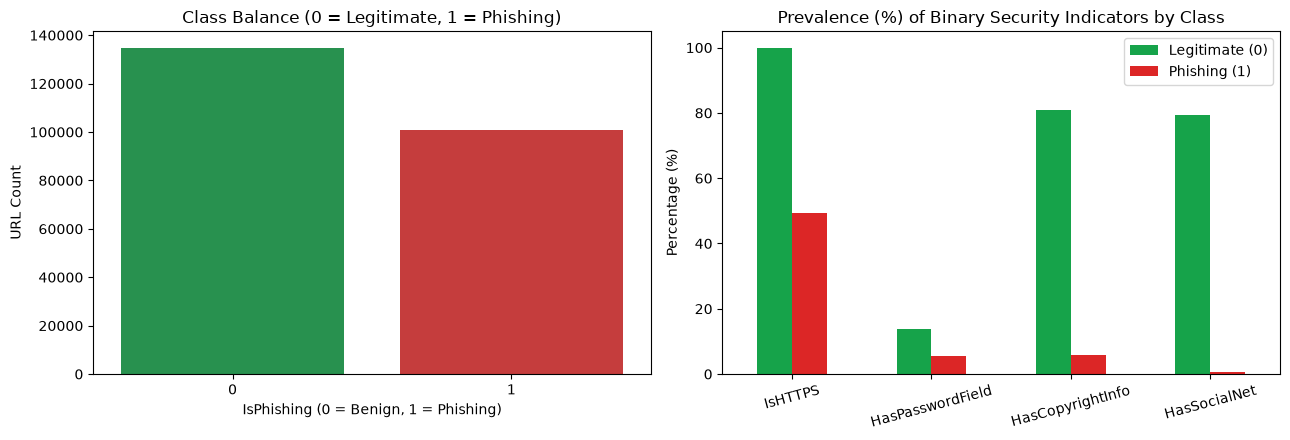

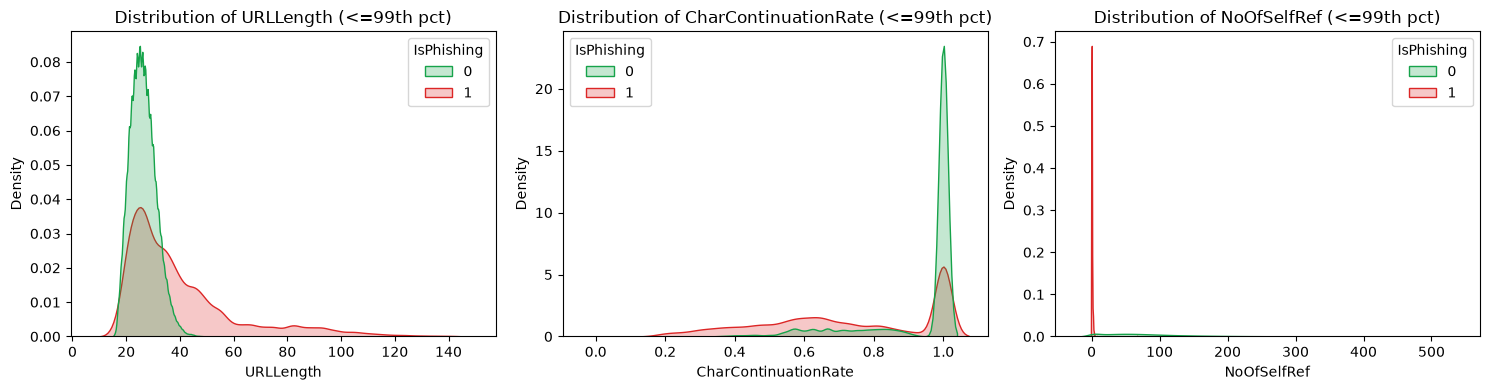

In [8]:
# EXERCISE 2: Visualizing Distributions and Binary Security Indicators

binary_cols = ['IsHTTPS', 'HasPasswordField', 'HasCopyrightInfo', 'HasSocialNet']
num_cols = ['URLLength', 'CharContinuationRate', 'NoOfSelfRef']

binary_stats = df.groupby('IsPhishing')[binary_cols].mean() * 100

print("Percentage (%) of URLs presenting each binary indicator per class (0=Benign, 1=Phishing):")
display(binary_stats.round(2))

# 1. Class Balance & Binary Indicators Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(
    data=df, x='IsPhishing', hue='IsPhishing',
    ax=axes[0], palette=['#16a34a', '#dc2626'], legend=False
)

axes[0].set_title("Class Balance (0 = Legitimate, 1 = Phishing)")
axes[0].set_xlabel("IsPhishing (0 = Benign, 1 = Phishing)")
axes[0].set_ylabel("URL Count")

binary_stats.T.plot(kind='bar', ax=axes[1], color=['#16a34a', '#dc2626'])

axes[1].set_title("Prevalence (%) of Binary Security Indicators by Class")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xticklabels(binary_cols, rotation=15)
axes[1].legend(["Legitimate (0)", "Phishing (1)"])

plt.tight_layout()
plt.show()

# 2. Numerical Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(num_cols):
    upper_clip = df[col].quantile(0.99)

    sns.kdeplot(
        data=df[df[col] <= upper_clip],
        x=col,
        hue='IsPhishing',
        common_norm=False,
        fill=True,
        palette=['#16a34a', '#dc2626'],
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col} (<=99th pct)")

plt.tight_layout()
plt.show()

---
### 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)

We remove raw text identifiers and the original label to avoid data leakage and improve model generalization.

Then, we construct the feature matrix X and target vector y and calculate Pearson correlations between numerical features and the phishing target.

Shape of X: (235795, 49) | Shape of y: (235795,)


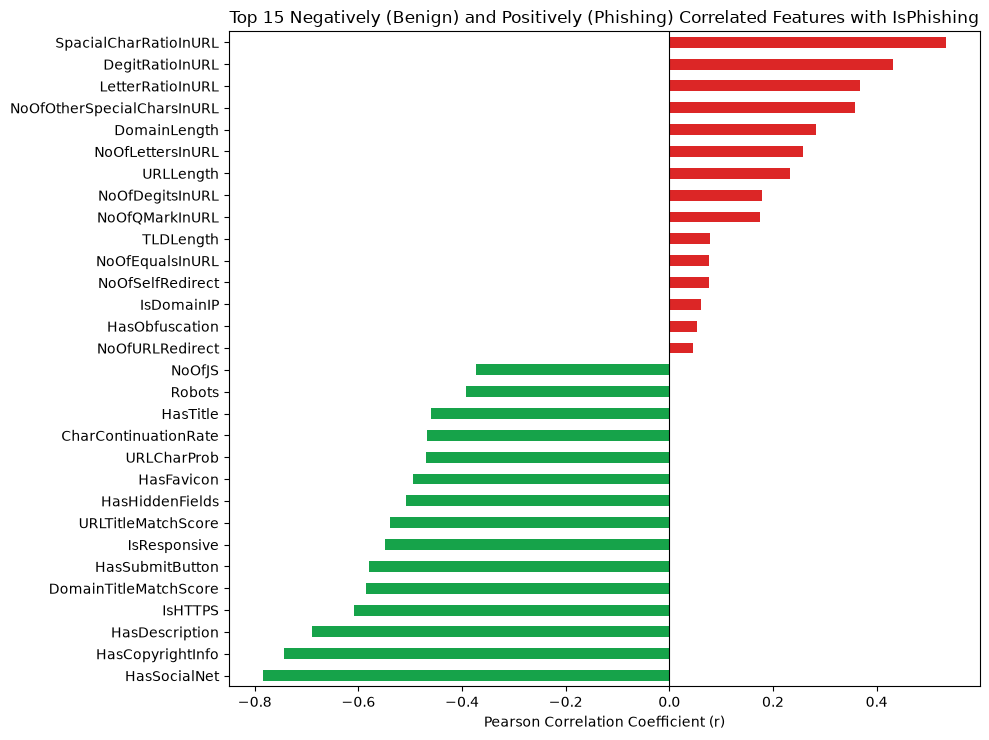

In [9]:
# EXERCISE 3: Constructing X, y and Analyzing Target Correlations

cols_to_drop = [
    'FILENAME', 'URL', 'Domain', 'TLD',
    'Title', 'label', 'IsPhishing', 'URLSimilarityIndex'
]

X = df.drop(columns=cols_to_drop)
y = df['IsPhishing']

correlations = X.corrwith(y).sort_values()

print("Shape of X:", X.shape, "| Shape of y:", y.shape)

# Plot Top 15 Negatively and Top 15 Positively Correlated Features
top_corr = pd.concat([correlations.head(15), correlations.tail(15)])

plt.figure(figsize=(10, 7.5))

colors = ['#16a34a' if c < 0 else '#dc2626' for c in top_corr.values]

top_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)

plt.title("Top 15 Negatively (Benign) and Positively (Phishing) Correlated Features with IsPhishing")
plt.xlabel("Pearson Correlation Coefficient (r)")

plt.tight_layout()
plt.show()

### 💡 Part 1 Reflection Questions

**1. Looking at your plot for `IsHTTPS`, what percentage of phishing sites currently use an HTTPS certificate? Why is a static rule "If HTTPS then Legitimate" dangerous?**

**Answer:** According to the dataset, approximately **49.22% of phishing websites use HTTPS**. Therefore, HTTPS does not guarantee that a website is legitimate. Phishing websites can also use valid SSL/TLS certificates. A static rule such as "If HTTPS then Legitimate" is dangerous because it may allow malicious websites to bypass security detection.

**2. Why do phishing websites typically have very few internal links (`NoOfSelfRef`) but very frequently contain a password field (`HasPasswordField`)?**

**Answer:** Phishing websites are usually designed to imitate legitimate login pages and steal users' credentials. They often contain password fields to capture sensitive information but have limited internal navigation because their main purpose is to collect credentials rather than provide complete website functionality.

**3. What would happen in production if we left the `FILENAME`, `URL`, or `Domain` column in our training matrix?**

**Answer:** Keeping these identifier columns could cause data leakage and overfitting. The model might memorize specific URLs, domain names, or filenames instead of learning general phishing patterns. Consequently, it may perform poorly on new and previously unseen websites in production.

---
## 3 - Part 2: Zero-Data Leakage Preprocessing & Standardization

In this part, we prepare the dataset for Machine Learning by splitting it into training and testing subsets and applying feature standardization.

We follow the zero-data leakage principle: the StandardScaler is fitted only on the training data.

### 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)

We split the dataset into 75% training data and 25% testing data using stratification to preserve the original class distribution.

Then, we fit the StandardScaler only on the training data and use it to transform both subsets.

In [10]:
# EXERCISE 4: Stratified Split and Leakage-Free Standardization

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=SEED
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Retain column names and indices for interpretability
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X.columns,
    index=X_test.index
)

print("Train shape:", X_train_scaled.shape, "| Test shape:", X_test_scaled.shape)
print("Mean of X_train_scaled (URLLength):", round(X_train_scaled['URLLength'].mean(), 4))
print("Std of X_train_scaled (URLLength):", round(X_train_scaled['URLLength'].std(), 4))

Train shape: (176846, 49) | Test shape: (58949, 49)
Mean of X_train_scaled (URLLength): -0.0
Std of X_train_scaled (URLLength): 1.0


### 💡 Part 2 Reflection Questions

**1. Compare the scale of `LineOfCode` (values up to 10,000+) and `IsHTTPS` (0 or 1) before standardization. Why would L1/L2 regularization be skewed without `StandardScaler`?**

**Answer:** Features have very different numerical scales. `LineOfCode` can have values in the thousands, while `IsHTTPS` is only 0 or 1. Without standardization, regularization may penalize coefficients unevenly because features with different scales require different coefficient magnitudes. As a result, L1/L2 regularization could unfairly penalize some features and affect the model's performance. `StandardScaler` puts numerical features on a comparable scale.

**2. Precisely explain why calling `scaler.fit_transform(X)` before `train_test_split` constitutes Preprocessing Data Leakage.**

**Answer:** Calling `fit_transform(X)` before splitting the data calculates the mean and standard deviation using both training and testing data. This means information from the test set influences the preprocessing parameters used during training. In a real production scenario, the model would not have access to future or unseen data. This creates data leakage and can lead to an overly optimistic evaluation. The correct approach is to split the dataset first, fit the scaler only on `X_train`, then use `transform()` on `X_test`.

---
## 4 - Part 3: Parameterized Logistic Regression & Interpretability

In this part, we train and compare different Logistic Regression configurations to evaluate their performance in phishing detection.

We investigate the effects of regularization and class weighting on classification performance and model sparsity.

### 4.1 Comparing 5 Logistic Regression Configurations (Exercise 5)

We train five Logistic Regression models with different configurations:

- M1: Unregularized Logistic Regression.
- M2: Strong L2 Ridge Regularization (C = 0.001).
- M3: Standard L2 Ridge Regularization (C = 1.0).
- M4: Sparse L1 Lasso Regularization (C = 0.01).
- M5: SOC Weighted Logistic Regression (class_weight = balanced).

We compare their Precision, Recall, F1-Score, PR-AUC, False Positives, False Negatives, and model sparsity.

In [11]:
# EXERCISE 5: Training and Comparing 5 Logistic Regression Configurations

configurations = {
    "M1: Unregularized (None)": LogisticRegression(
        penalty=None, solver='lbfgs', max_iter=500, random_state=SEED
    ),
    "M2: Strong L2 Ridge (C=0.001)": LogisticRegression(
        penalty='l2', C=0.001, solver='lbfgs', max_iter=500, random_state=SEED
    ),
    "M3: Standard L2 Ridge (C=1.0)": LogisticRegression(
        penalty='l2', C=1.0, solver='lbfgs', max_iter=500, random_state=SEED
    ),
    "M4: Sparse L1 Lasso (C=0.01)": LogisticRegression(
        penalty='l1', C=0.01, solver='liblinear', max_iter=500, random_state=SEED
    ),
    "M5: SOC Weighted (balanced)": LogisticRegression(
        penalty='l2', C=1.0, class_weight='balanced',
        solver='lbfgs', max_iter=500, random_state=SEED
    ),
}

results = []

for name, model in configurations.items():

    model.fit(X_train_scaled, y_train)

    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = model.predict(X_test_scaled)

    w = model.coef_.ravel()
    n_zero_weights = np.sum(np.abs(w) < 1e-8)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall (TPR)": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1-Score": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 4),
        "False Alarms (FP)": int(fp),
        "Missed Phish (FN)": int(fn),
        "Zeroed Weights (Sparsity)": f"{n_zero_weights} / {len(w)}"
    })

results_df = pd.DataFrame(results)
display(results_df)

c:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logi

,Model,Precision,Recall (TPR),F1-Score,PR-AUC,False Alarms (FP),Missed Phish (FN),Zeroed Weights (Sparsity)
0,M1: Unregularized (None),0.9996,0.9990,0.9993,1.0,11,25,0 / 49
1,M2: Strong L2 Ridge (C=0.001),0.9985,0.9958,0.9971,1.0,39,105,0 / 49
2,M3: Standard L2 Ridge (C=1.0),0.9996,0.9989,0.9992,1.0,10,28,0 / 49
3,M4: Sparse L1 Lasso (C=0.01),0.9993,0.9971,0.9982,1.0,18,72,24 / 49
4,M5: SOC Weighted (balanced),0.9995,0.9990,0.9992,1.0,13,25,0 / 49


---
### 4.2 L1 Regularization Path & Feature Selection (Exercise 6)

In this exercise, we investigate the effect of L1 regularization on feature selection.

We vary the regularization parameter C and count the number of active features. A feature is considered active when its coefficient has an absolute value greater than or equal to 10^-4.

Training L1 model with C=1.0...


c:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Active features: 49
Zeroed features: 0
Total features: 49


c:\Users\HP\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,C,Active Features,Zeroed Features
0,1.0,49,0


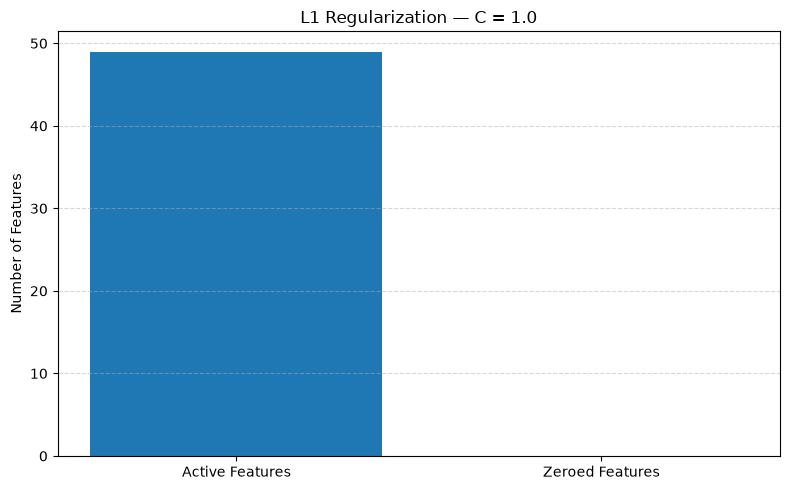

In [12]:
# EXERCISE 6: L1 Regularization Path (C = 1.0)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression

# Train L1 model
print("Training L1 model with C=1.0...", flush=True)

m_l1 = LogisticRegression(
    penalty='l1',
    C=1.0,
    solver='liblinear',
    max_iter=500,
    random_state=42
)

m_l1_fit = m_l1.fit(X_train_scaled, y_train)

# Count active features
n_active = np.sum(
    np.abs(m_l1_fit.coef_[0]) >= 1e-4
)

total_features = X.shape[1]
n_zeroed = total_features - n_active

print("Active features:", n_active)
print("Zeroed features:", n_zeroed)
print("Total features:", total_features)

# Results table
results = pd.DataFrame({
    "C": [1.0],
    "Active Features": [n_active],
    "Zeroed Features": [n_zeroed]
})

display(results)

# Plot
plt.figure(figsize=(8, 5))

plt.bar(
    ["Active Features", "Zeroed Features"],
    [n_active, n_zeroed]
)

plt.ylabel("Number of Features")
plt.title("L1 Regularization — C = 1.0")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
### 4.3 Interpreting Coefficients (w_j) and Odds Ratios (e^w_j) (Exercise 7)

In this exercise, we analyze the coefficients learned by the standard L2 model (M3) and compare them with the sparse L1 model (M4).

The Odds Ratio is calculated using the exponential of each coefficient.

Positive coefficients push predictions toward phishing, while negative coefficients push predictions toward legitimate URLs.

In [13]:
# EXERCISE 7: Inspecting Log-Odds and Odds Ratios

model_l2 = configurations["M3: Standard L2 Ridge (C=1.0)"]
model_l1 = configurations["M4: Sparse L1 Lasso (C=0.01)"]

weights_df = pd.DataFrame({
    "L2_Weight": model_l2.coef_.ravel(),
    "Odds_Ratio": np.exp(model_l2.coef_.ravel()),
    "L1_Weight": model_l1.coef_.ravel()
}, index=X.columns)

weights_df = weights_df.sort_values(
    by="L2_Weight",
    ascending=False
)

print("TOP 8 FEATURES PUSHING TOWARD PHISHING (w_j > 0):")
display(weights_df.head(8).round(4))

print("\nTOP 8 FEATURES PUSHING TOWARD BENIGN (w_j < 0):")
display(weights_df.tail(8).round(4))

TOP 8 FEATURES PUSHING TOWARD PHISHING (w_j > 0):


,L2_Weight,Odds_Ratio,L1_Weight
LetterRatioInURL,4.7228,112.4883,2.1726
DegitRatioInURL,3.6057,36.8079,1.8036
SpacialCharRatioInURL,3.5981,36.5306,1.9106
LargestLineLength,2.5575,12.9038,0.0848
NoOfOtherSpecialCharsInURL,2.0834,8.0315,0.0000
NoOfLettersInURL,1.6801,5.3660,0.0000
CharContinuationRate,1.4202,4.1378,0.0000
NoOfDegitsInURL,0.9718,2.6426,0.0000



TOP 8 FEATURES PUSHING TOWARD BENIGN (w_j < 0):


,L2_Weight,Odds_Ratio,L1_Weight
DomainLength,-1.9117,0.1478,-0.0585
HasSocialNet,-2.1533,0.1161,-1.0887
LineOfCode,-2.3676,0.0937,0.0000
NoOfExternalRef,-2.6414,0.0713,-0.0157
NoOfImage,-2.7981,0.0609,-0.1505
NoOfSelfRef,-3.1249,0.0439,-0.8227
NoOfJS,-3.6536,0.0259,-1.2017
IsHTTPS,-6.9024,0.0010,-3.5777


### Part 3 Reflection Questions

**1. How many variables did M4 eliminate? Did the F1-Score drop significantly? What is the advantage for a real-time firewall?**

The number of eliminated variables is determined by the zeroed weights reported for M4 in the model comparison table. L1 regularization performs feature selection by setting some coefficients to zero. This can reduce model complexity, improve efficiency, and make real-time detection faster.

**2. What is the impact of class_weight='balanced' (M5) on False Positives and False Negatives compared to M3?**

The balanced class weighting gives more importance to the minority class during training. It can improve phishing detection and reduce False Negatives, but may increase False Positives. The actual impact must be verified using the results table.

**3. How do you interpret a positive weight versus a negative weight?**

A positive coefficient (w_j > 0) increases the log-odds of phishing detection. A negative coefficient (w_j < 0) decreases the log-odds and pushes the prediction toward a legitimate URL.

---
## 5 - Part 4: Explainable AI (SHAP) & SOC Threshold Analysis

In this part, we use SHAP (SHapley Additive exPlanations) to understand the decisions made by the Logistic Regression model.

We analyze global feature importance, individual predictions, and operational decision thresholds for SOC environments.

### 5.1 Global Explanations with shap.LinearExplainer (Exercise 8)

We use SHAP LinearExplainer to explain the predictions of the standard L2 Logistic Regression model (M3).

We calculate SHAP values for the first 1,000 test URLs and visualize global feature importance using Bar and Beeswarm plots.

Background dataset has 176846 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=176846 when initializing the masker.


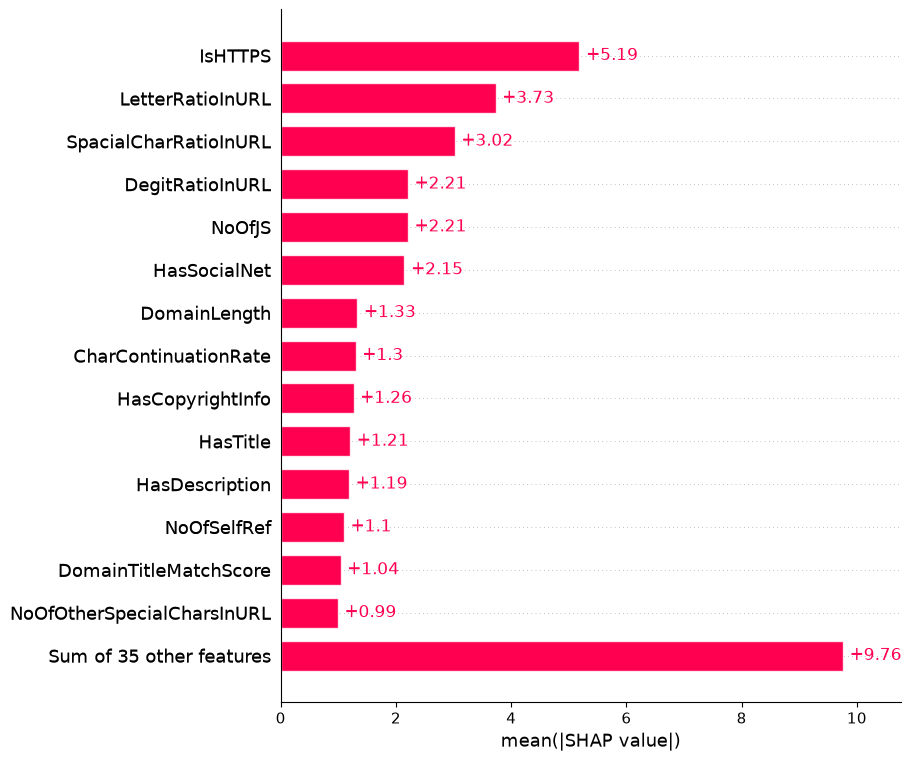

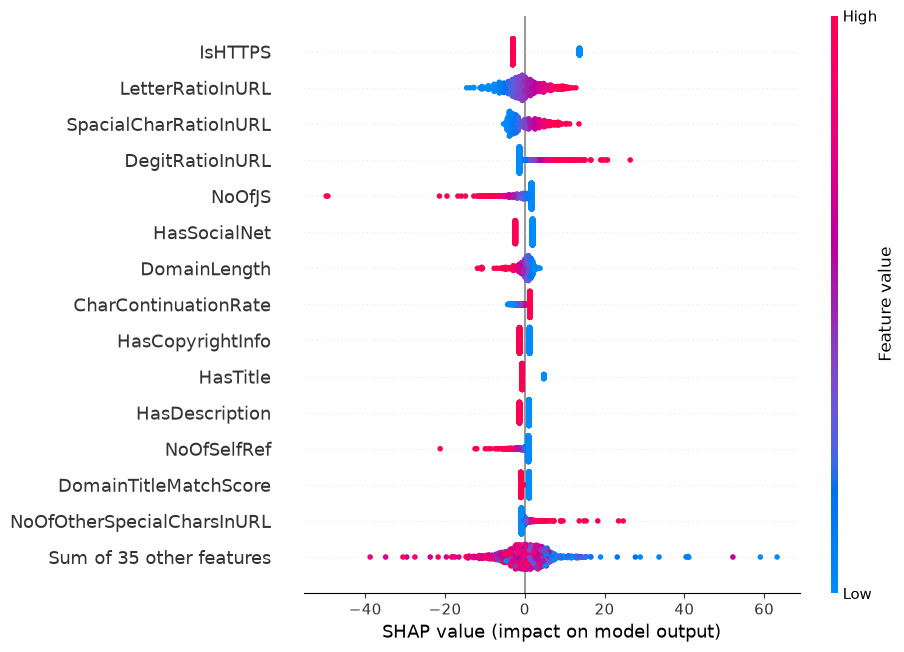

In [14]:
# EXERCISE 8: Computing SHAP Values and Global Importance Plots

X_test_sample = X_test_scaled.iloc[:1000]

explainer = shap.LinearExplainer(
    model_l2,
    X_train_scaled
)

shap_values = explainer(X_test_sample)

# 1. Global Mean Absolute SHAP Importance
shap.plots.bar(shap_values, max_display=15)

# 2. Global Directional Impact
shap.plots.beeswarm(shap_values, max_display=15)

---
### 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)

In this exercise, we select three individual test cases:

- True Positive (TP): A phishing URL correctly detected.
- True Negative (TN): A legitimate URL correctly classified.
- False Positive (FP): A legitimate URL incorrectly classified as phishing.

We use SHAP Waterfall plots to understand which features contributed to each prediction.

TP cases: 24928
TN cases: 9767
FP cases: 23946

Selected cases:
TP index: 2
TN index: 3
FP index: 0

CASE 1: TRUE POSITIVE - Phishing correctly detected
Test index: 2
True label: 1
Predicted label: 1
Phishing probability: 100.00%


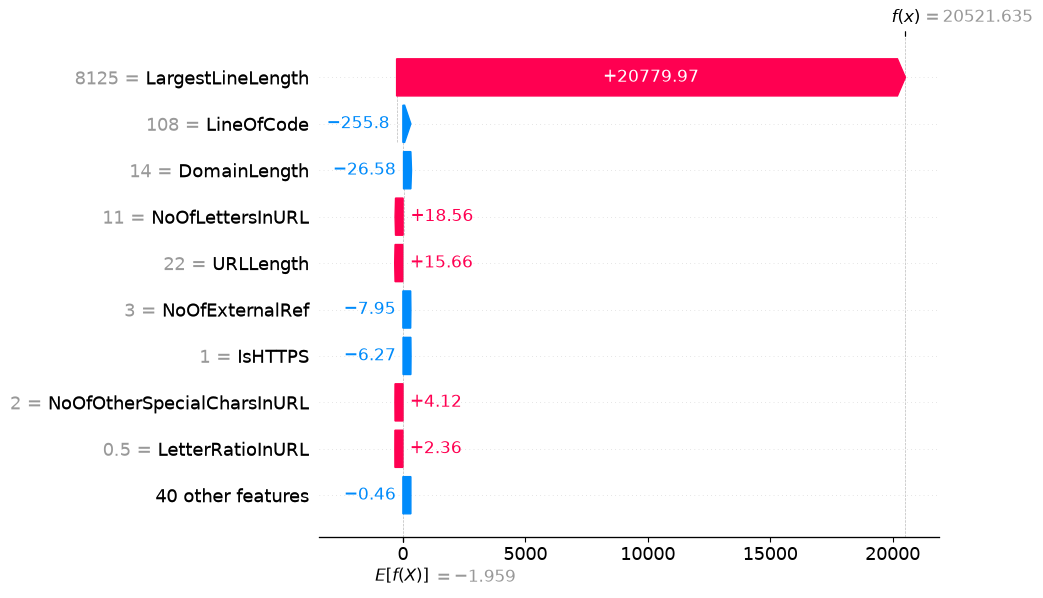


CASE 2: TRUE NEGATIVE - Legitimate URL correctly classified
Test index: 3
True label: 0
Predicted label: 0
Phishing probability: 0.00%


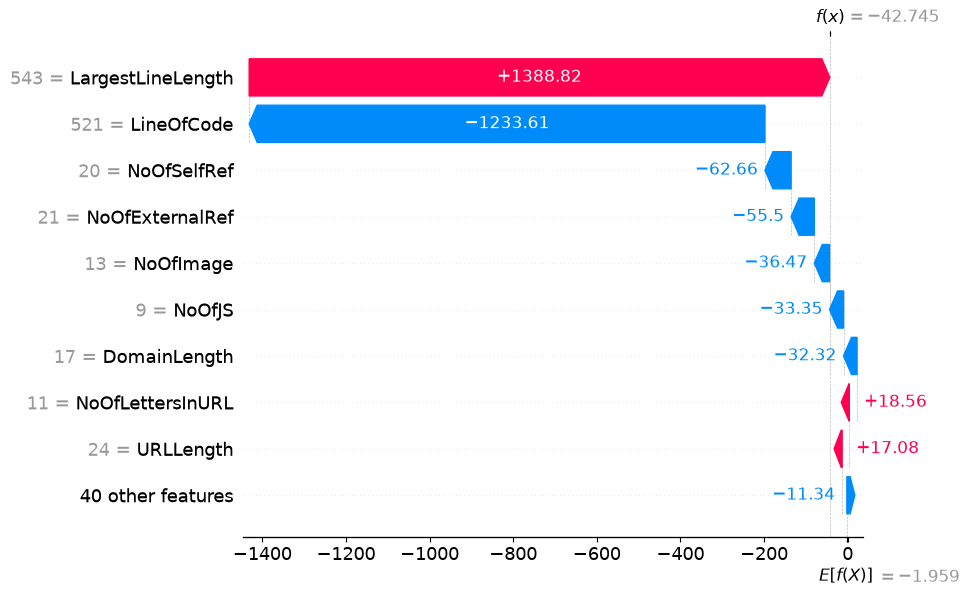


CASE 3: FALSE POSITIVE - Legitimate URL incorrectly flagged
Test index: 0
True label: 0
Predicted label: 1
Phishing probability: 100.00%


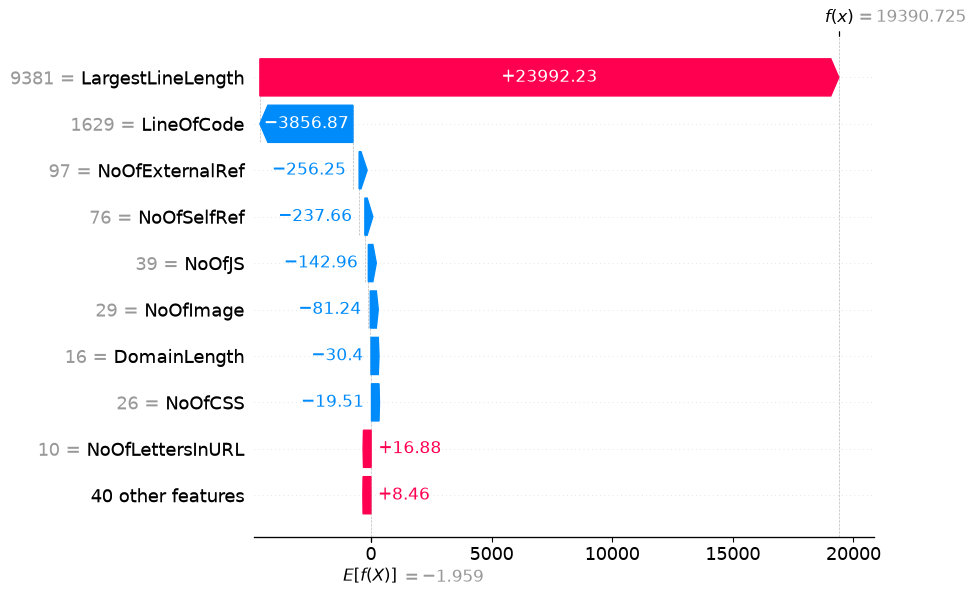

In [19]:

# EXERCISE 9: Local SOC Triage of TP, TN, and FP Cases with SHAP Waterfall

import numpy as np
import shap
import matplotlib.pyplot as plt

# 1. Use the complete test dataset
y_test_array = np.asarray(y_test).ravel()

y_prob = model_l2.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.50).astype(int)

# 2. Find TP, TN, and FP cases
tp_candidates = np.where((y_test_array == 1) & (y_pred == 1))[0]
tn_candidates = np.where((y_test_array == 0) & (y_pred == 0))[0]
fp_candidates = np.where((y_test_array == 0) & (y_pred == 1))[0]

print("TP cases:", len(tp_candidates))
print("TN cases:", len(tn_candidates))
print("FP cases:", len(fp_candidates))

# 3. Check that all required cases exist
if len(tp_candidates) == 0:
    raise ValueError("No True Positive case found.")

if len(tn_candidates) == 0:
    raise ValueError("No True Negative case found.")

if len(fp_candidates) == 0:
    raise ValueError("No False Positive case found.")

# 4. Select the first case of each type
tp_idx = int(tp_candidates[0])
tn_idx = int(tn_candidates[0])
fp_idx = int(fp_candidates[0])

print("\nSelected cases:")
print("TP index:", tp_idx)
print("TN index:", tn_idx)
print("FP index:", fp_idx)

# 5. Calculate SHAP values for the selected samples
selected_indices = [tp_idx, tn_idx, fp_idx]
X_selected = X_test.iloc[selected_indices]

# Use the same SHAP explainer created in the previous exercise
selected_shap_values = explainer(X_selected)

# 6. Plot SHAP waterfall for each case
def plot_soc_waterfall(position, case_title, original_idx):

    true_label = y_test_array[original_idx]
    predicted_label = y_pred[original_idx]
    phishing_probability = y_prob[original_idx] * 100

    print("\n" + "=" * 65)
    print(case_title)
    print("Test index:", original_idx)
    print("True label:", true_label)
    print("Predicted label:", predicted_label)
    print(f"Phishing probability: {phishing_probability:.2f}%")
    print("=" * 65)

    shap.plots.waterfall(
        selected_shap_values[position],
        max_display=10,
        show=True
    )

# CASE 1: TRUE POSITIVE
plot_soc_waterfall(
    0,
    "CASE 1: TRUE POSITIVE - Phishing correctly detected",
    tp_idx
)

# CASE 2: TRUE NEGATIVE
plot_soc_waterfall(
    1,
    "CASE 2: TRUE NEGATIVE - Legitimate URL correctly classified",
    tn_idx
)

# CASE 3: FALSE POSITIVE
plot_soc_waterfall(
    2,
    "CASE 3: FALSE POSITIVE - Legitimate URL incorrectly flagged",
    fp_idx
)


---
### 5.3 Operational Decision Threshold Tuning (Exercise 10)

In this exercise, we evaluate the standard L2 model (M3) using three decision thresholds:

- 0.20: Threat Hunting Mode, prioritizing Recall.
- 0.50: Default Mode, using the standard classification threshold.
- 0.85: Automated Firewall Blocking Mode, prioritizing Precision.

The objective is to understand how changing the threshold affects False Positives, False Negatives, Precision, and Recall.

In [17]:
# EXERCISE 10: Comparing Operational Decision Thresholds

y_prob_full = model_l2.predict_proba(X_test_scaled)[:, 1]

thresholds = [0.20, 0.50, 0.85]
threshold_records = []

for tau in thresholds:

    y_pred_tau = (y_prob_full >= tau).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_tau,
        labels=[0, 1]
    ).ravel()

    threshold_records.append({
        "Threshold (tau)": tau,
        "SOC Operational Mode": (
            "Threat Hunting" if tau == 0.20
            else ("Default" if tau == 0.50
                  else "Automated Blocking")
        ),
        "Precision": round(
            precision_score(y_test, y_pred_tau, zero_division=0), 4
        ),
        "Recall (TPR)": round(
            recall_score(y_test, y_pred_tau, zero_division=0), 4
        ),
        "F1-Score": round(
            f1_score(y_test, y_pred_tau, zero_division=0), 4
        ),
        "True Positives (TP)": int(tp),
        "True Negatives (TN)": int(tn),
        "False Positives (FP)": int(fp),
        "False Negatives (FN)": int(fn)
    })

threshold_df = pd.DataFrame(threshold_records)

display(threshold_df)

,Threshold (tau),SOC Operational Mode,Precision,Recall (TPR),F1-Score,True Positives (TP),True Negatives (TN),False Positives (FP),False Negatives (FN)
0,0.20,Threat Hunting,0.9988,0.9994,0.9991,25221,33682,31,15
1,0.50,Default,0.9996,0.9989,0.9992,25208,33703,10,28
2,0.85,Automated Blocking,1.0000,0.9975,0.9987,25172,33713,0,64


### Part 4 Reflection Questions

**1. What is the mathematical difference between a global weight w_j and a local SHAP value φ_j(x)?**

A global model weight (w_j) represents the learned influence of a feature on the model's log-odds across all predictions. A local SHAP value (φ_j(x)) represents the contribution of a specific feature to the prediction of one individual URL, relative to the model's baseline prediction.

**2. On your False Positive Waterfall plot, which 2 or 3 features misled the model?**

The features with the largest positive SHAP values in the False Positive case pushed the prediction toward phishing. These features can be identified using the FP SHAP explanation and the Top 3 features table.

**3. Why would a SOC deploy τ = 0.85 for automated blocking while routing URLs with 0.20 ≤ P(Phishing) < 0.85 to a human analyst?**

A high threshold such as 0.85 helps reduce False Positives and avoids automatically blocking legitimate business traffic. URLs with intermediate phishing probabilities can be sent to human analysts for additional investigation. A lower threshold can be used for threat hunting to identify more potential phishing attacks.

---
## 6 - Conclusion & SOC Engineering Synthesis

This lab demonstrated how Machine Learning can support phishing URL detection in a Security Operations Center.

The workflow included exploratory data analysis, leakage-free preprocessing, Logistic Regression model comparison, L1 feature selection, model interpretability using coefficients and Odds Ratios, and explainability using SHAP.

The final analysis also demonstrated how operational decision thresholds can be adapted to different SOC security requirements.